# Activity 1: Multiple Linear Regression — California Housing Price Prediction

**Course:** Regression and Classification Algorithms (RCA) — CIE 2 Activity 1 (Unit I)  
**Role:** Data Scientist at a Real-Estate Analytics Organisation  
**Dataset:** California Housing Prices (1990 US Census — Kaggle / Cam Nugent)  
**Source:** [California Housing Prices on Kaggle](https://www.kaggle.com/datasets/camnugent/california-housing-prices)

---

### Professional Data Scientist Decision Log (Summary)

| Decision Area | Choice Made | Alternatives Considered | Reason for Choice |
| :--- | :--- | :--- | :--- |
| **Problem Framing** | Predict `median_house_value` (USD) using 6 numerical block-group features | Classification into price tiers | Continuous price estimation directly supports property valuation and urban planning budgets. |
| **Feature Selection** | 6 numerical features: `median_income`, `housing_median_age`, `total_rooms`, `total_bedrooms`, `population`, `households` | Include `longitude`, `latitude`, `ocean_proximity` | Activity 1 focuses on numerical Multiple Linear Regression; geographic coordinates require non-linear/spatial encoding. |
| **Missing Values** | Drop 207 rows (~1.0%) missing `total_bedrooms` | Median imputation | Dropping ~1% of 20,640 rows avoids artificial imputation bias and keeps 20,433 complete records with zero leakage. |
| **Outliers / Cap** | Retain the `$500,001` census cap rows | Remove capped rows | Preserves dataset integrity; documented as a known data limitation affecting upper-end residuals. |
| **Baseline** | Mean-prediction baseline + Single-feature Linear Regression (`median_income`) | None | A model is only useful if it beats a simple mean benchmark and justifies added feature complexity. |
| **Model Limits** | Do not use for individual property appraisals or automated mortgage lending | Deploy directly | Block-group averages from 1990 census data cannot price individual homes or replace human appraisers. |

## Step 1: Introduction and Problem Statement

### 1.1 What is Multiple Linear Regression?
**Multiple Linear Regression (MLR)** models the linear relationship between a continuous dependent variable ($y$) and two or more independent input features ($X_1, X_2, \dots, X_p$):

$$y = b_0 + b_1 X_1 + b_2 X_2 + \dots + b_p X_p + \epsilon$$

where:
- $b_0$ is the **intercept** (baseline value when all features are zero),
- $b_1, b_2, \dots, b_p$ are the **partial regression coefficients** (change in $y$ for a 1-unit increase in $X_i$, holding all other features constant),
- $\epsilon$ is the **error term (residual)** capturing unexplained variation.

### 1.2 Real-World Problem & Stakeholder Context
As a data analyst at a real-estate analytics organisation, our goal is to **estimate median house prices across California census block groups** to support housing market research and urban planning.

- **Dependent Variable ($y$):** `median_house_value` — Median house value for households within a block group (measured in **USD**).
- **Independent Variables ($X$):**
  1. `median_income`: Median income for households within a block group (measured in **tens of thousands of USD**, e.g., `3.5` = `$35,000`). Higher-income neighborhoods generally afford higher-priced homes.
  2. `housing_median_age`: Median age of houses in the block group (**years**). Older neighborhoods may reflect either historic/established value or aging infrastructure.
  3. `total_rooms`: Total number of rooms across all homes in the block group (**count**). Reflects neighborhood housing stock size.
  4. `total_bedrooms`: Total number of bedrooms across all homes in the block group (**count**). Closely tied to housing capacity and family size.
  5. `population`: Total number of people residing in the block group (**count**). Indicates neighborhood density and housing demand.
  6. `households`: Total number of households in the block group (**count**). Reflects occupied housing units and local demand.

### 1.3 Why Multiple Linear Regression is Useful Here
House prices are rarely driven by a single factor alone. While income is a strong driver, neighborhood age, housing capacity, and population density also play simultaneous roles. Multiple Linear Regression lets us quantify the contribution of each factor while **interpreting coefficients in clear real-world units**.

## Step 2: Dataset Loading and Understanding

We import our Python libraries, record library versions and random seed (`random_state=42`) for reproducibility, load the dataset (using local `../data/housing.csv` or downloading from GitHub if run in Google Colab), and perform thorough quality checks.

In [1]:
# Import required libraries
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import statsmodels
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Reproducibility settings
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")

print(f"Python: {sys.version.split()[0]}")
print(f"NumPy: {np.__version__} | Pandas: {pd.__version__} | Scikit-learn: {sklearn.__version__} | Statsmodels: {statsmodels.__version__}")

Python: 3.14.4
NumPy: 2.5.4 | Pandas: 3.1.0 | Scikit-learn: 1.9.1 | Statsmodels: 0.15.0


In [2]:
# Define paths (compatible with both local execution and Google Colab)
DATA_URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
local_data_path = Path("../data/housing.csv")
out_dir = Path("../outputs/generated_visualizations")
out_dir.mkdir(parents=True, exist_ok=True)

if local_data_path.exists():
    df_raw = pd.read_csv(local_data_path)
    print(f"Loaded dataset from local file: {local_data_path}")
else:
    df_raw = pd.read_csv(DATA_URL)
    print("Loaded dataset from remote URL (Colab/standalone mode).")

print(f"Raw Dataset Shape: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns")
df_raw.head()

Loaded dataset from local file: ../data/housing.csv
Raw Dataset Shape: 20640 rows x 10 columns


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.2300,37.8800,41.0000,880.0000,129.0000,322.0000,126.0000,8.3252,"452,600.0000",NEAR BAY
1,-122.2200,37.8600,21.0000,"7,099.0000","1,106.0000","2,401.0000","1,138.0000",8.3014,"358,500.0000",NEAR BAY
2,-122.2400,37.8500,52.0000,"1,467.0000",190.0000,496.0000,177.0000,7.2574,"352,100.0000",NEAR BAY
3,-122.2500,37.8500,52.0000,"1,274.0000",235.0000,558.0000,219.0000,5.6431,"341,300.0000",NEAR BAY
4,-122.2500,37.8500,52.0000,"1,627.0000",280.0000,565.0000,259.0000,3.8462,"342,200.0000",NEAR BAY


In [3]:
# Inspect data types, missing values, and duplicate records
print("--- Data Types & Non-Null Counts ---")
df_raw.info()

print("\n--- Missing Values per Column ---")
print(df_raw.isnull().sum())

print(f"\nExact Duplicate Rows: {df_raw.duplicated().sum()}")

--- Data Types & Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB

--- Missing Values per Column ---
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_incom

In [4]:
# Descriptive statistics for selected features and target
FEATURES = [
    "median_income",
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
]
TARGET = "median_house_value"

df_raw[FEATURES + [TARGET]].describe().T[["count", "mean", "std", "min", "50%", "max"]]

,count,mean,std,min,50%,max
median_income,"20,640.0000",3.8707,1.8998,0.4999,3.5348,15.0001
housing_median_age,"20,640.0000",28.6395,12.5856,1.0000,29.0000,52.0000
total_rooms,"20,640.0000","2,635.7631","2,181.6153",2.0000,"2,127.0000","39,320.0000"
total_bedrooms,"20,433.0000",537.8706,421.3851,1.0000,435.0000,"6,445.0000"
population,"20,640.0000","1,425.4767","1,132.4621",3.0000,"1,166.0000","35,682.0000"
households,"20,640.0000",499.5397,382.3298,1.0000,409.0000,"6,082.0000"
median_house_value,"20,640.0000","206,855.8169","115,395.6159","14,999.0000","179,700.0000","500,001.0000"


In [5]:
# Data Cleaning: Drop rows with missing values in selected columns and remove any duplicates
df = df_raw.dropna(subset=FEATURES + [TARGET]).drop_duplicates().reset_index(drop=True)

rows_removed = len(df_raw) - len(df)
print(f"Rows before cleaning: {len(df_raw)}")
print(f"Rows after cleaning : {len(df)} ({rows_removed} rows removed, {rows_removed / len(df_raw) * 100:.2f}%)")
print(f"Remaining missing values in selected columns: {df[FEATURES + [TARGET]].isnull().sum().sum()}")

Rows before cleaning: 20640
Rows after cleaning : 20433 (207 rows removed, 1.00%)
Remaining missing values in selected columns: 0


**Cleaning Decision Explanation:**
- Only `total_bedrooms` had missing values (**207 out of 20,640 rows**, or **1.00%**). Removing these 207 rows leaves **20,433 complete observations** with zero artificial imputation bias and zero risk of train-test leakage.
- There were **0 exact duplicate rows**.
- Notice in `describe()` that `median_house_value` has a maximum of **`$500,001`** (a census reporting cap) and `housing_median_age` has a maximum of **52 years**. We retain these records to preserve dataset integrity and will account for this ceiling effect during residual analysis.

## Step 3: Exploratory Data Analysis (EDA)

Before fitting any model, we visualize the target distribution, feature-target relationships, and inter-feature correlations.

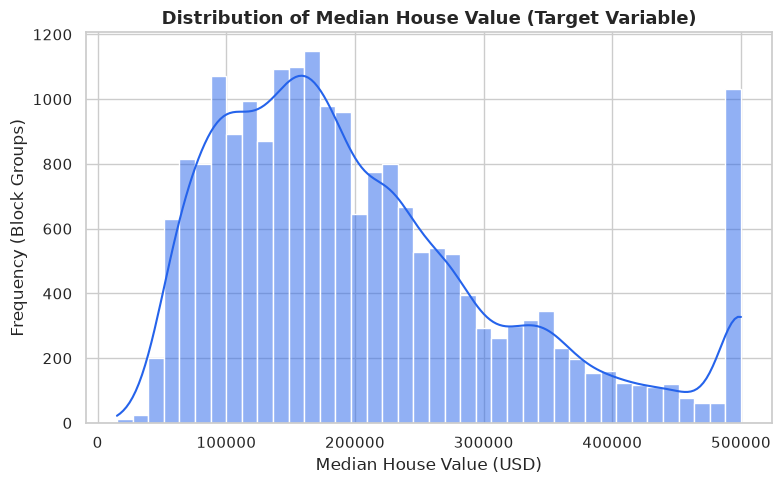

In [6]:
# 1. Target variable distribution
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(df[TARGET], bins=40, kde=True, color="#2563eb", ax=ax)
ax.set_title("Distribution of Median House Value (Target Variable)", fontsize=13, fontweight="bold")
ax.set_xlabel("Median House Value (USD)")
ax.set_ylabel("Frequency (Block Groups)")
fig.tight_layout()
fig.savefig(out_dir / "01_target_distribution.png", dpi=150)
plt.show()

**Observation (Target Distribution):**
- `median_house_value` is **right-skewed**, with most block groups clustered between `$100,000` and `$265,000`.
- There is a sharp spike at **`$500,001`** caused by the 1990 US Census upper cap, which will make predicting very expensive homes harder for a linear model.

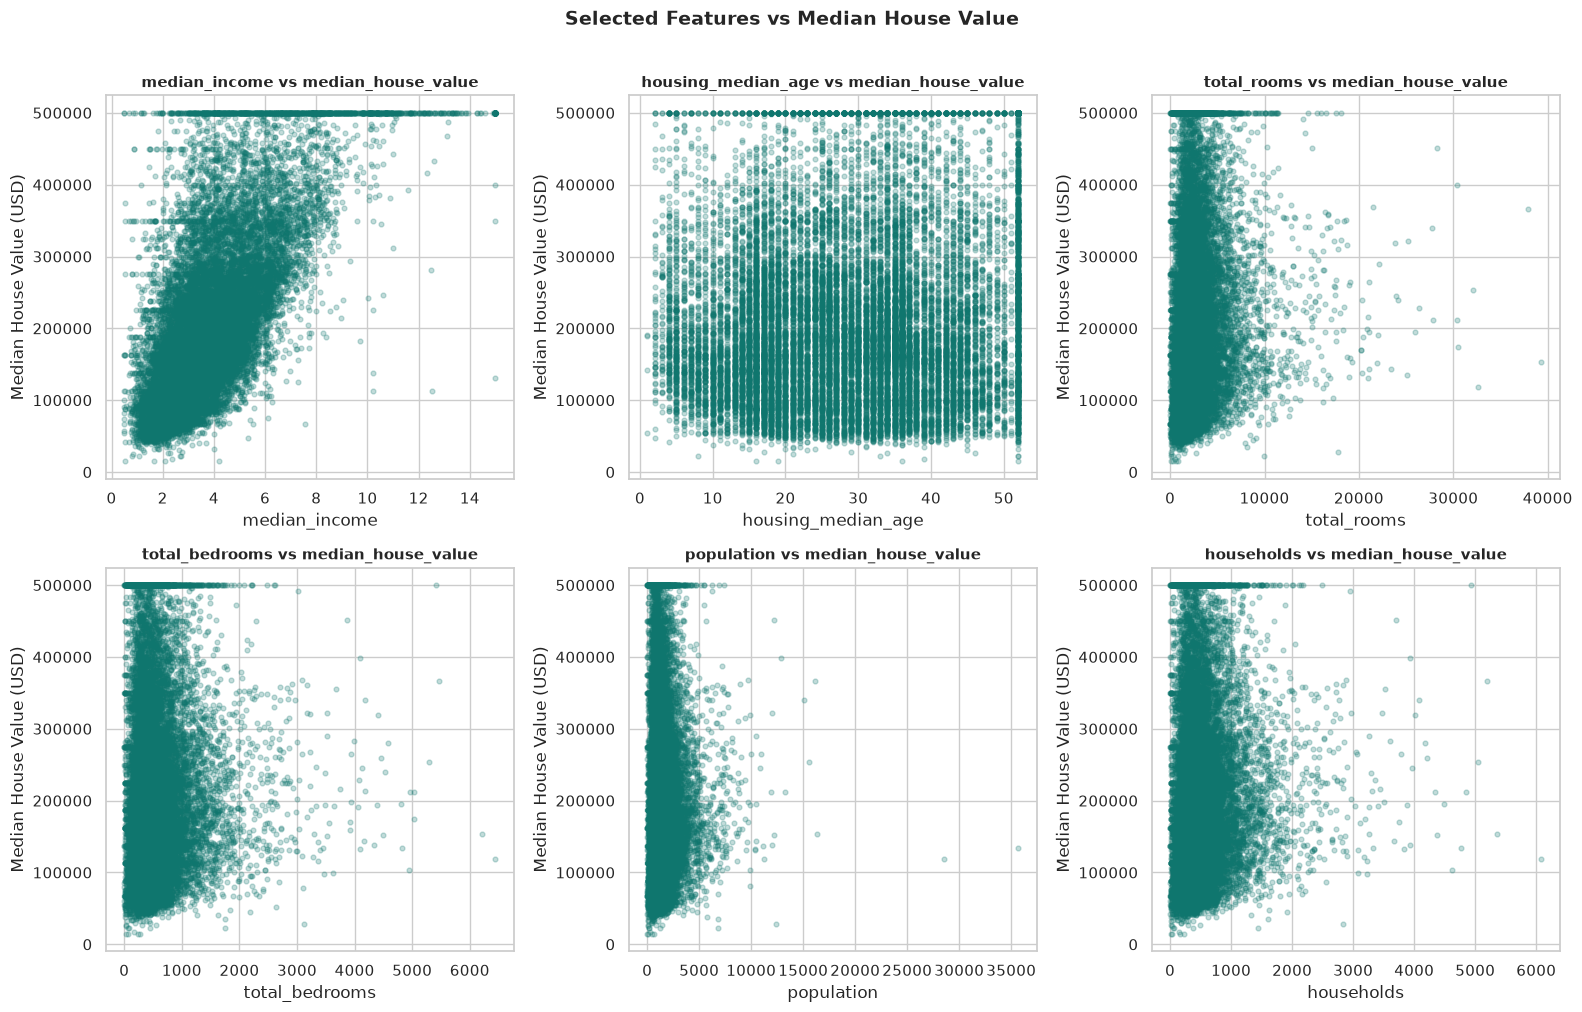

In [7]:
# 2. Scatter plots of each selected feature against median_house_value
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, feat in zip(axes.flat, FEATURES):
    ax.scatter(df[feat], df[TARGET], alpha=0.25, s=12, color="#0f766e")
    ax.set_title(f"{feat} vs {TARGET}", fontsize=11, fontweight="bold")
    ax.set_xlabel(feat)
    ax.set_ylabel("Median House Value (USD)")

fig.suptitle("Selected Features vs Median House Value", fontsize=14, fontweight="bold", y=1.01)
fig.tight_layout()
fig.savefig(out_dir / "02_feature_scatter_plots.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation (Feature Scatter Plots):**
- `median_income` shows a **clear positive linear trend** with `median_house_value` — neighborhoods with higher median incomes consistently have higher house values.
- `housing_median_age` shows a very weak positive spread, while `total_rooms`, `total_bedrooms`, `population`, and `households` are heavily concentrated near smaller counts with a few large block-group outliers.
- A horizontal line of points is visible at `y = 500,001` across all plots due to the census price cap.

,median_income,housing_median_age,total_rooms,total_bedrooms,population,households,median_house_value
median_income,1.0000,-0.1183,0.1979,-0.0077,0.0051,0.0134,0.6884
housing_median_age,-0.1183,1.0000,-0.3606,-0.3205,-0.2958,-0.3028,0.1064
total_rooms,0.1979,-0.3606,1.0000,0.9304,0.8573,0.9190,0.1333
total_bedrooms,-0.0077,-0.3205,0.9304,1.0000,0.8777,0.9797,0.0497
population,0.0051,-0.2958,0.8573,0.8777,1.0000,0.9072,-0.0253
households,0.0134,-0.3028,0.9190,0.9797,0.9072,1.0000,0.0649
median_house_value,0.6884,0.1064,0.1333,0.0497,-0.0253,0.0649,1.0000


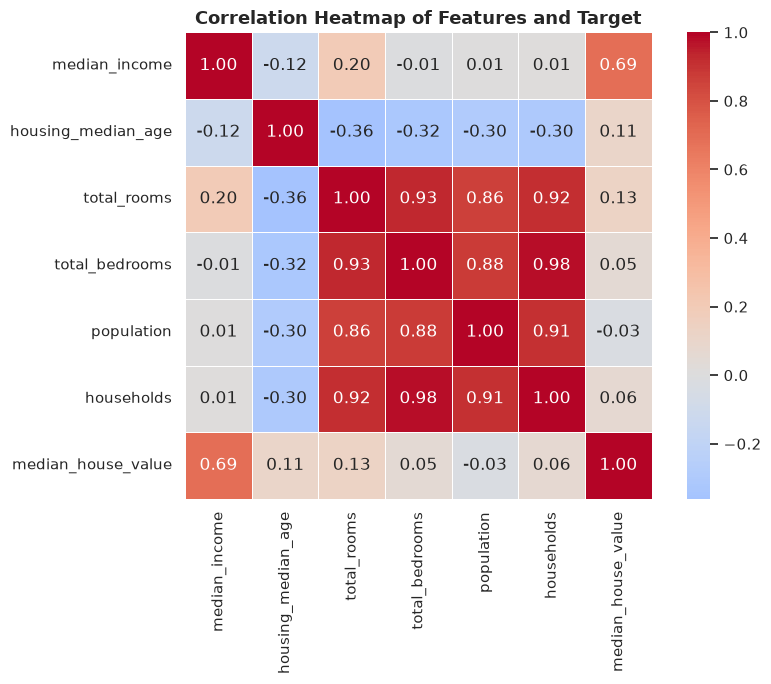

In [8]:
# 3. Correlation matrix and labelled heatmap
corr_matrix = df[FEATURES + [TARGET]].corr()
display(corr_matrix)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlation Heatmap of Features and Target", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(out_dir / "03_correlation_heatmap.png", dpi=150)
plt.show()

**Observation (Correlation Matrix & Heatmap):**
- **Feature–Target Correlations:** `median_income` has the strongest correlation with `median_house_value` ($r = +0.69$), making it the best candidate for Single Linear Regression. `total_rooms` ($r = +0.13$) and `housing_median_age` ($r = +0.11$) have weak positive correlations, while `total_bedrooms`, `households`, and `population` are near zero.
- **Inter-Feature Correlations (Multicollinearity Warning):** `total_bedrooms` and `households` ($r = 0.98$), `total_rooms` and `total_bedrooms` ($r = 0.93$), `total_rooms` and `households` ($r = 0.92$), and `population` and `households` ($r = 0.91$) are **very strongly correlated**. This indicates severe multicollinearity among the block-group size features.
- **Important Reminder:** *Correlation does not prove causation.* A high correlation only shows statistical association, not that one variable directly causes the other.

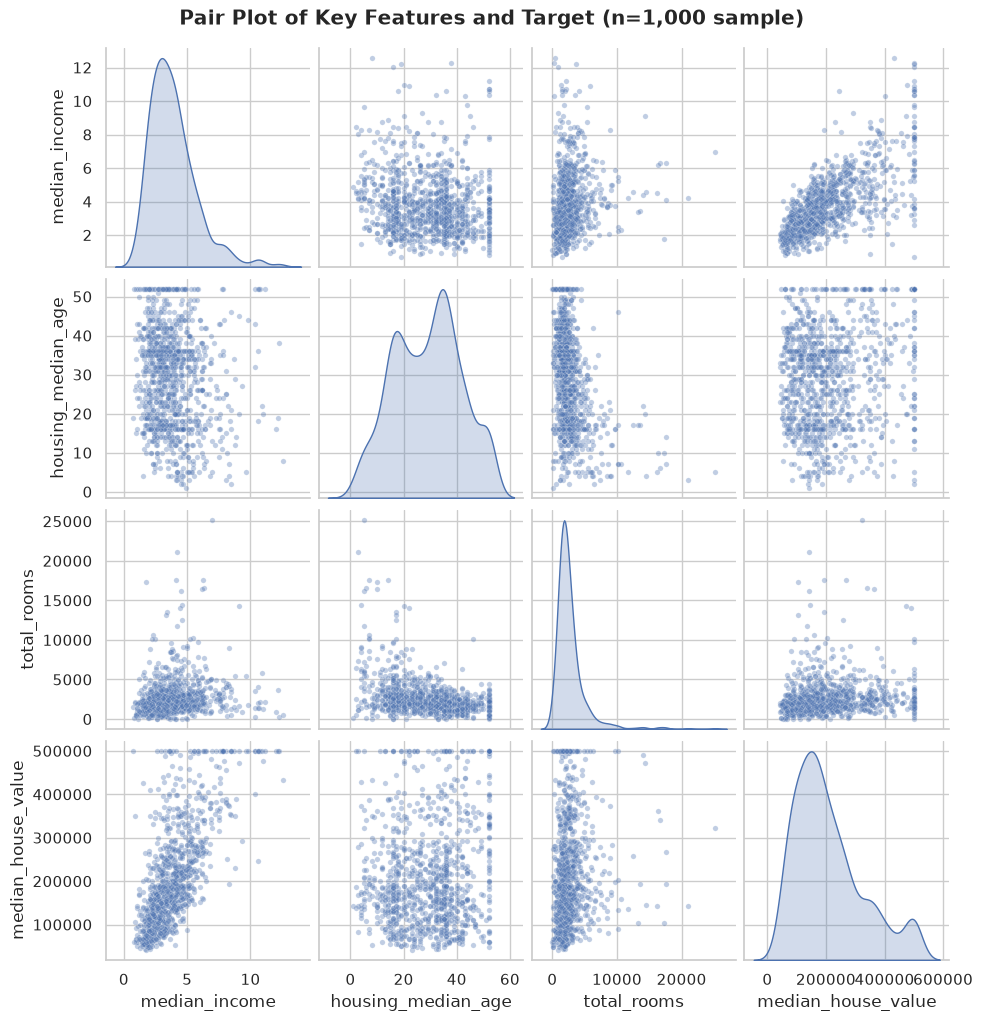

In [9]:
# 4. Pair plot on a 1,000-row random sample of key features and target
pair_sample = df[["median_income", "housing_median_age", "total_rooms", TARGET]].sample(
    n=1000, random_state=RANDOM_STATE
)
pair_grid = sns.pairplot(pair_sample, diag_kind="kde", plot_kws={"alpha": 0.35, "s": 15})
pair_grid.fig.suptitle("Pair Plot of Key Features and Target (n=1,000 sample)", y=1.02, fontweight="bold")
pair_grid.savefig(out_dir / "04_pair_plot.png", dpi=130, bbox_inches="tight")
plt.show()

**Observation (Pair Plot):**
- The diagonal KDE plots confirm `median_income` and `total_rooms` are right-skewed, whereas `housing_median_age` is more evenly spread between 1 and 52 years.
- The `median_income` vs `median_house_value` panel clearly shows the strongest upward linear band.

## Step 4: Manual Multiple Linear Regression Calculation (Compulsory)

To understand the exact mathematical mechanics behind Multiple Linear Regression, we manually solve the **Normal Equations** on a small sample of **6 observations** (rows 0–5 of the cleaned dataset) using two numerical features:
- $X_1 = 	ext{median\_income}$ (tens of thousands of USD)
- $X_2 = 	ext{housing\_median\_age}$ (years)
- $y = 	ext{median\_house\_value}$ (USD)

The Normal Equations are:
$$(X^T X)\mathbf{b} = X^T \mathbf{y} \implies \mathbf{b} = (X^T X)^{-1} X^T \mathbf{y}$$

In [10]:
# Select 6 observations and 2 numerical features
sample_df = df[["median_income", "housing_median_age", TARGET]].iloc[:6].copy().reset_index(drop=True)
print("--- Original Sample Observation Table (n = 6) ---")
display(sample_df)

x1 = sample_df["median_income"].to_numpy()
x2 = sample_df["housing_median_age"].to_numpy()
y_sample = sample_df[TARGET].to_numpy()

# Design matrix X: [1, X1, X2]
X_design = np.column_stack([np.ones(len(sample_df)), x1, x2])
Xt = X_design.T
XtX = Xt @ X_design
Xty = Xt @ y_sample
det_XtX = np.linalg.det(XtX)
XtX_inv = np.linalg.inv(XtX)
b_manual = XtX_inv @ Xty

np.set_printoptions(precision=4, suppress=True)
print("\nDesign Matrix X (6 x 3):\n", X_design)
print("\nTarget Vector y (6 x 1):\n", y_sample)
print("\nX Transpose (X^T) (3 x 6):\n", Xt)
print("\nX^T X (3 x 3):\n", XtX)
print(f"\ndet(X^T X) = {det_XtX:,.4f}")
print("\nX^T y (3 x 1):\n", Xty)
print("\n(X^T X)^(-1):\n", XtX_inv)
print("\nSolved Coefficients b = [b0, b1, b2]:\n", b_manual)

--- Original Sample Observation Table (n = 6) ---


,median_income,housing_median_age,median_house_value
0,8.3252,41.0000,"452,600.0000"
1,8.3014,21.0000,"358,500.0000"
2,7.2574,52.0000,"352,100.0000"
3,5.6431,52.0000,"341,300.0000"
4,3.8462,52.0000,"342,200.0000"
5,4.0368,52.0000,"269,700.0000"



Design Matrix X (6 x 3):
 [[ 1.      8.3252 41.    ]
 [ 1.      8.3014 21.    ]
 [ 1.      7.2574 52.    ]
 [ 1.      5.6431 52.    ]
 [ 1.      3.8462 52.    ]
 [ 1.      4.0368 52.    ]]

Target Vector y (6 x 1):
 [452600. 358500. 352100. 341300. 342200. 269700.]

X Transpose (X^T) (3 x 6):
 [[ 1.      1.      1.      1.      1.      1.    ]
 [ 8.3252  8.3014  7.2574  5.6431  3.8462  4.0368]
 [41.     21.     52.     52.     52.     52.    ]]

X^T X (3 x 3):
 [[    6.        37.4101   270.    ]
 [   37.4101   253.8256  1596.4046]
 [  270.      1596.4046 12938.    ]]

det(X^T X) = 51,803.2275

X^T y (3 x 1):
 [ 2116400.   13630252.59 93960700.  ]

(X^T X)^(-1):
 [[14.1977 -1.0228 -0.1701]
 [-1.0228  0.0913  0.0101]
 [-0.1701  0.0101  0.0024]]

Solved Coefficients b = [b0, b1, b2]:
 [125635.9161  26774.5776   1336.8329]


In [11]:
# Final sample regression equation, manual prediction, and residual for Observation 0
b0, b1, b2 = b_manual
print(f"Sample Regression Equation:")
print(f"  y_hat = {b0:,.4f} + ({b1:,.4f}) * median_income + ({b2:,.4f}) * housing_median_age")

# Manual prediction for Observation 0
x1_0, x2_0, y_0 = x1[0], x2[0], y_sample[0]
y_hat_0 = b0 + b1 * x1_0 + b2 * x2_0
residual_0 = y_0 - y_hat_0

print(f"\nManual Prediction for Observation 0 (median_income={x1_0}, housing_median_age={x2_0}):")
print(f"  y_hat_0 = {b0:,.4f} + ({b1:,.4f} * {x1_0}) + ({b2:,.4f} * {x2_0}) = ${y_hat_0:,.2f}")
print(f"  Actual y_0 = ${y_0:,.2f}")
print(f"  Residual (y_0 - y_hat_0) = ${residual_0:,.2f}")

# Verify with Scikit-learn on the exact same 6-row sample
sk_sample_model = LinearRegression().fit(sample_df[["median_income", "housing_median_age"]], y_sample)
b_sklearn = np.array([sk_sample_model.intercept_, sk_sample_model.coef_[0], sk_sample_model.coef_[1]])
diff = np.abs(b_manual - b_sklearn)

verify_df = pd.DataFrame({
    "Parameter": ["b0 (Intercept)", "b1 (median_income)", "b2 (housing_median_age)"],
    "Manual_Normal_Eq": b_manual,
    "Scikit_Learn": b_sklearn,
    "Absolute_Difference": diff,
})
print("\n--- Verification: Manual Calculation vs Scikit-learn ---")
display(verify_df)

Sample Regression Equation:
  y_hat = 125,635.9161 + (26,774.5776) * median_income + (1,336.8329) * housing_median_age

Manual Prediction for Observation 0 (median_income=8.3252, housing_median_age=41.0):
  y_hat_0 = 125,635.9161 + (26,774.5776 * 8.3252) + (1,336.8329 * 41.0) = $403,349.78
  Actual y_0 = $452,600.00
  Residual (y_0 - y_hat_0) = $49,250.22

--- Verification: Manual Calculation vs Scikit-learn ---


,Parameter,Manual_Normal_Eq,Scikit_Learn,Absolute_Difference
0,b0 (Intercept),"125,635.9161","125,635.9161",0.0000
1,b1 (median_income),"26,774.5776","26,774.5776",0.0000
2,b2 (housing_median_age),"1,336.8329","1,336.8329",0.0000


**Observation (Manual OLS Verification):**
- The manual Normal Equation solution gives $b_0 = 125,635.9161$, $b_1 = 26,774.5776$, and $b_2 = 1,336.8329$.
- Scikit-learn produces the **exact same coefficients** (difference $< 10^{-10}$, purely due to floating-point arithmetic).

## Step 5: Train-Test Split

We split the cleaned dataset into **80% training** and **20% testing** sets with `random_state=42`. All fitting, scaling, and feature analysis are performed strictly on the training set to prevent **data leakage**. We also compute a **Mean Baseline** (predicting the training mean for every test sample).

In [12]:
X = df[FEATURES]
y = df[TARGET].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f"Total cleaned observations: {len(df)}")
print(f"Training set observations : {len(X_train)} ({len(X_train)/len(df)*100:.1f}%)")
print(f"Testing set observations  : {len(X_test)} ({len(X_test)/len(df)*100:.1f}%)")

# Simple mean-based baseline
y_pred_baseline = np.full(shape=len(y_test), fill_value=y_train.mean(), dtype=float)
print(f"Training Mean Baseline Prediction: ${y_train.mean():,.2f}")

Total cleaned observations: 20433
Training set observations : 16346 (80.0%)
Testing set observations  : 4087 (20.0%)
Training Mean Baseline Prediction: $206,644.40


## Step 6: Single Linear Regression

From Step 3, `median_income` has the strongest linear correlation with `median_house_value` ($r = 0.69$). We train a single-feature baseline model using `median_income` on the training set only.

In [13]:
slr_model = LinearRegression()
slr_model.fit(X_train[["median_income"]], y_train)
y_pred_slr = slr_model.predict(X_test[["median_income"]])

slr_r2 = r2_score(y_test, y_pred_slr)
print(f"Single Linear Regression Intercept  : ${slr_model.intercept_:,.2f}")
print(f"Single Linear Regression Coefficient: ${slr_model.coef_[0]:,.2f} per unit of median_income")
print(f"Single Linear Regression Test R^2   : {slr_r2:.4f}")

Single Linear Regression Intercept  : $45,035.23
Single Linear Regression Coefficient: $41,751.96 per unit of median_income
Single Linear Regression Test R^2   : 0.4720


## Step 7: Multiple Linear Regression

We train Multiple Linear Regression using all 6 selected features on the training data only. We also fit a `StandardScaler` on the training data only to inspect **standardized coefficients** (allowing fair comparison of relative feature influence regardless of units).

In [14]:
mlr_model = LinearRegression()
mlr_model.fit(X_train, y_train)
y_pred_mlr = mlr_model.predict(X_test)

# Standardized coefficients (fit scaler on training data ONLY)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
mlr_scaled = LinearRegression().fit(X_train_scaled, y_train)

coef_table = pd.DataFrame({
    "Feature": FEATURES,
    "Unit": [
        "10,000 USD",
        "Years",
        "Rooms (count)",
        "Bedrooms (count)",
        "People (count)",
        "Households (count)",
    ],
    "Raw_Coefficient": mlr_model.coef_,
    "Standardized_Coefficient": mlr_scaled.coef_,
})

print(f"Multiple Linear Regression Intercept (b0): ${mlr_model.intercept_:,.2f}")
display(coef_table)

Multiple Linear Regression Intercept (b0): $-45,966.35


,Feature,Unit,Raw_Coefficient,Standardized_Coefficient
0,median_income,"10,000 USD","47,698.9661","90,521.5070"
1,housing_median_age,Years,"1,880.9047","23,655.7389"
2,total_rooms,Rooms (count),-19.8859,"-42,819.1900"
3,total_bedrooms,Bedrooms (count),104.9803,"43,824.8387"
4,population,People (count),-33.6260,"-37,975.2267"
5,households,Households (count),116.3150,"43,965.4287"


### Complete Mathematical Regression Equation

$$\widehat{\text{median\_house\_value}} = -45,966.35 + 47,698.97(\text{median\_income}) + 1,880.90(\text{housing\_median\_age}) - 19.89(\text{total\_rooms}) + 104.98(\text{total\_bedrooms}) - 33.63(\text{population}) + 116.32(\text{households})$$

### Plain-English Interpretation of Intercept and Coefficients
- **Intercept (`-$45,966.35`):** Mathematically, this is the predicted house value when all 6 features are zero. In the real world, a block group with zero rooms, zero households, and zero income cannot exist, so the intercept is **not physically meaningful**—it simply anchors the regression plane.
- **`median_income` (`+$47,698.97`):** Holding all other features constant, a 1-unit increase in median income (`+$10,000`) is associated with an average **`$47,698.97` increase** in median house value.
- **`housing_median_age` (`+$1,880.90`):** Holding other features constant, each additional year of median housing age is associated with a **`$1,880.90` increase** in median house value (older established coastal/urban areas in California tend to be pricier).
- **`total_rooms` (`-$19.89`):** Holding `total_bedrooms` and `households` constant, each extra room is associated with a **`$19.89` decrease**. Note that this negative sign is a classic **multicollinearity artifact** (individually `total_rooms` is positively correlated with house value, $r = +0.13$).
- **`total_bedrooms` (`+$104.98`):** Holding other features constant, each additional bedroom in the block group is associated with a **`$104.98` increase** in median house value.
- **`population` (`-$33.63`):** Holding households and rooms constant, each additional resident is associated with a **`$33.63` decrease** in median house value (higher crowding per household lowers property value).
- **`households` (`+$116.32`):** Holding population and bedrooms constant, each additional household is associated with a **`$116.32` increase** in median house value.
- **Standardized Comparison:** Looking at the standardized coefficients (effect of a 1-standard-deviation change), `median_income` (`+90,521.51`) is by far the **strongest driver** of house value—more than double any other feature. Remember that these coefficients describe statistical associations, not causal proof.

## Step 8: Model Predictions

We generate predictions strictly on the **test set** (`X_test`), compare actual vs predicted prices side by side, plot Actual vs Predicted values, and make one new prediction using reasonable in-range values.

In [15]:
# Side-by-side Actual vs Predicted table (first 15 test observations)
pred_df = pd.DataFrame({
    "Actual_Price_USD": y_test[:15],
    "Predicted_Price_USD": y_pred_mlr[:15],
    "Error_Actual_Minus_Pred": y_test[:15] - y_pred_mlr[:15],
    "Abs_Error_USD": np.abs(y_test[:15] - y_pred_mlr[:15]),
})
display(pred_df)

,Actual_Price_USD,Predicted_Price_USD,Error_Actual_Minus_Pred,Abs_Error_USD
0,"245,800.0000","165,480.2275","80,319.7725","80,319.7725"
1,"137,900.0000","161,093.7265","-23,193.7265","23,193.7265"
2,"218,200.0000","196,854.0688","21,345.9312","21,345.9312"
3,"220,800.0000","154,256.5417","66,543.4583","66,543.4583"
4,"170,500.0000","199,116.5340","-28,616.5340","28,616.5340"
5,"75,000.0000","131,060.8854","-56,060.8854","56,060.8854"
6,"269,400.0000","257,916.8767","11,483.1233","11,483.1233"
7,"228,900.0000","253,836.8253","-24,936.8253","24,936.8253"
8,"500,001.0000","381,125.0022","118,875.9978","118,875.9978"
9,"80,800.0000","121,476.6725","-40,676.6725","40,676.6725"


**Observation (Actual vs Predicted Sample):**
- For mid-range homes (`$150,000`–`$250,000`), predictions are often within `$10,000`–`$40,000` of the actual price.
- Larger errors occur for high-value homes (especially near the `$500,001` cap) and coastal neighborhoods, because our 6 features do not include geographic location (`latitude`, `longitude`, `ocean_proximity`).

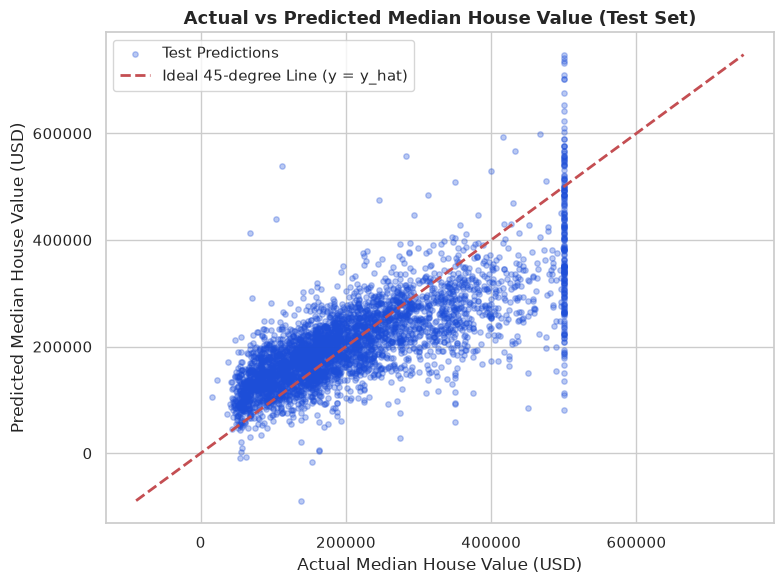

In [16]:
# Plot Actual vs Predicted with ideal 45-degree line
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_test, y_pred_mlr, alpha=0.3, s=15, color="#1d4ed8", label="Test Predictions")
lims = [min(y_test.min(), y_pred_mlr.min()), max(y_test.max(), y_pred_mlr.max())]
ax.plot(lims, lims, "r--", linewidth=2, label="Ideal 45-degree Line (y = y_hat)")
ax.set_title("Actual vs Predicted Median House Value (Test Set)", fontsize=13, fontweight="bold")
ax.set_xlabel("Actual Median House Value (USD)")
ax.set_ylabel("Predicted Median House Value (USD)")
ax.legend()
fig.tight_layout()
fig.savefig(out_dir / "05_actual_vs_predicted.png", dpi=150)
plt.show()

In [17]:
# New house-price prediction using reasonable in-range feature values
new_block_group = pd.DataFrame([{
    "median_income": 4.5,       # $45,000 median household income
    "housing_median_age": 25.0, # 25 years median age
    "total_rooms": 2200.0,      # 2,200 total rooms
    "total_bedrooms": 420.0,    # 420 total bedrooms
    "population": 1100.0,       # 1,100 residents
    "households": 400.0,        # 400 households
}])

# Verify all values are within training min-max range
in_range = (
    (new_block_group.iloc[0] >= X_train.min()) &
    (new_block_group.iloc[0] <= X_train.max())
).all()

new_pred = mlr_model.predict(new_block_group)[0]
print("New Input Record:")
display(new_block_group)
print(f"All values within training data range (no extrapolation): {in_range}")
print(f"Predicted Median House Value: ${new_pred:,.2f} USD")

New Input Record:


,median_income,housing_median_age,total_rooms,total_bedrooms,population,households
0,4.5000,25.0000,"2,200.0000",420.0000,"1,100.0000",400.0000


All values within training data range (no extrapolation): True
Predicted Median House Value: $225,581.72 USD


## Step 9: Evaluation Metrics

We evaluate the **Mean Baseline**, **Single Linear Regression**, and **Multiple Linear Regression** on the unseen test set using MAE, MSE, RMSE, $R^2$, and Adjusted $R^2$.

In [18]:
def evaluate_regression(y_true, y_pred, n_features):
    n = len(y_true)
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - n_features - 1)
    return {"MAE (USD)": mae, "MSE": mse, "RMSE (USD)": rmse, "R2": r2, "Adjusted R2": adj_r2}

results_df = pd.DataFrame([
    {"Model": "Mean Baseline (Train Mean)", **evaluate_regression(y_test, y_pred_baseline, 1)},
    {"Model": "Single Linear Regression (median_income)", **evaluate_regression(y_test, y_pred_slr, 1)},
    {"Model": "Multiple Linear Regression (6 features)", **evaluate_regression(y_test, y_pred_mlr, len(FEATURES))},
])
display(results_df)

,Model,MAE (USD),MSE,RMSE (USD),R2,Adjusted R2
0,Mean Baseline (Train Mean),"92,836.5012","13,676,390,692.8183","116,946.1017",-0.0001,-0.0003
1,Single Linear Regression (median_income),"63,374.5513","7,221,011,204.2350","84,976.5333",0.4720,0.4718
2,Multiple Linear Regression (6 features),"56,642.4993","5,865,619,646.9593","76,587.3335",0.5711,0.5704


### Metric Definitions & Interpretation
1. **MAE (Mean Absolute Error — `$56,642.50`):** The average absolute difference between actual and predicted house prices. On average, our multiple regression model is off by about `$56,643`.
2. **MSE (Mean Squared Error — `5.87e9`):** The average squared error. Squaring penalizes large errors heavily, making MSE sensitive to outliers.
3. **RMSE (Root Mean Squared Error — `$76,587.33`):** Square root of MSE, bringing the error back into **USD**. Because RMSE (`$76,587`) is noticeably larger than MAE (`$56,643`), there are some large prediction errors (especially on high-priced homes).
4. **$R^2$ Score (`0.5711`):** Our 6-feature model explains **57.11%** of the variance in unseen test house prices, compared to `0.00%` for the mean baseline.
5. **Adjusted $R^2$ (`0.5704`):** Penalizes adding features that contribute little. Since Adjusted $R^2$ (`0.5704`) is nearly identical to $R^2$ (`0.5711`), the added features genuinely improve predictive power on this large dataset.

### Single-Feature vs Multiple-Feature Comparison
- Adding the 5 additional features improved **Test $R^2$ from `0.4720` to `0.5711`** (+9.91 percentage points) and **Adjusted $R^2$ from `0.4718` to `0.5704`**, while reducing **RMSE from `$84,977` to `$76,587`** (a `$8,390` reduction in typical error) and **MAE from `$63,375` to `$56,643`**.
- **Conclusion:** Yes, the extra features improved the model enough to justify the added complexity, though multicollinearity among the room/household/population features should still be addressed.

## Step 10: Residual Analysis

We examine the test-set residuals ($e = y_{\text{actual}} - \hat{y}_{\text{predicted}}$) to diagnose where and why the model makes errors.

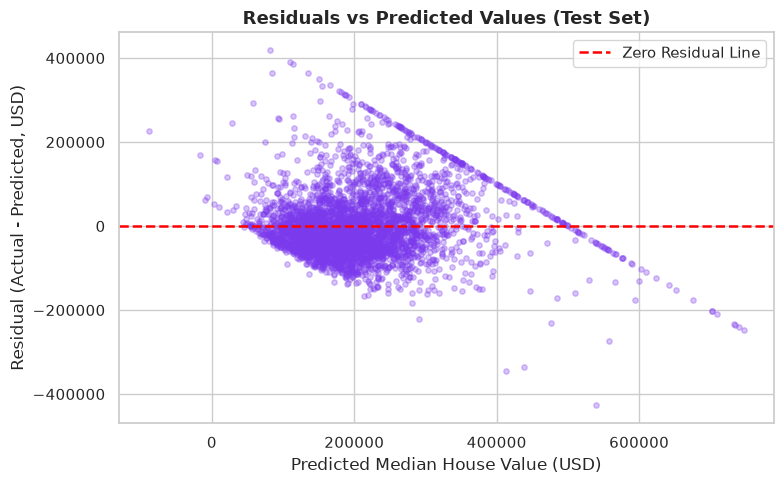

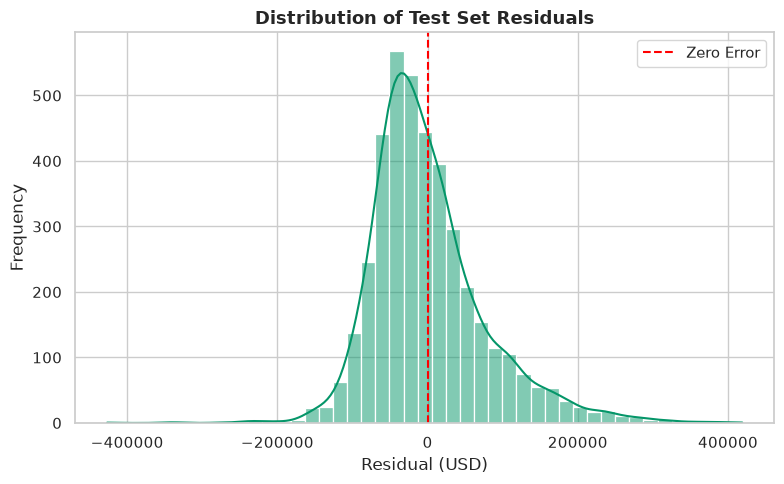

In [19]:
residuals = y_test - y_pred_mlr

# 1. Residuals vs Predicted Values
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(y_pred_mlr, residuals, alpha=0.3, s=15, color="#7c3aed")
ax.axhline(0, color="red", linestyle="--", linewidth=1.8, label="Zero Residual Line")
ax.set_title("Residuals vs Predicted Values (Test Set)", fontsize=13, fontweight="bold")
ax.set_xlabel("Predicted Median House Value (USD)")
ax.set_ylabel("Residual (Actual - Predicted, USD)")
ax.legend()
fig.tight_layout()
fig.savefig(out_dir / "06_residuals_vs_predicted.png", dpi=150)
plt.show()

# 2. Residual Distribution Histogram
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(residuals, bins=45, kde=True, color="#059669", ax=ax)
ax.axvline(0, color="red", linestyle="--", linewidth=1.5, label="Zero Error")
ax.set_title("Distribution of Test Set Residuals", fontsize=13, fontweight="bold")
ax.set_xlabel("Residual (USD)")
ax.set_ylabel("Frequency")
ax.legend()
fig.tight_layout()
fig.savefig(out_dir / "07_residual_histogram.png", dpi=150)
plt.show()

**Observations from Residual & Diagnostic Plots:**
1. **Residuals vs Predicted Values:** The spread of residuals widens slightly as predicted price increases (a mild funnel shape), indicating **heteroscedasticity** (non-constant error variance). A diagonal upper boundary is also visible due to the `$500,001` census price cap.
2. **Residual Distribution Histogram:** The residuals are centered near zero and roughly bell-shaped in the middle, but have a **right tail (positive skew)** where actual house prices are much higher than linear predictions.
3. **Actual vs Predicted (Step 8 plot):** Points cluster around the ideal 45-degree line in the `$100k–$300k` range, but scatter more widely above `$350k` and hit a flat ceiling at `$500,001`.

## Step 11: Multicollinearity

Multicollinearity occurs when independent variables are strongly correlated with each other, making individual regression coefficients unstable and hard to interpret. We check both the feature correlation matrix and the **Variance Inflation Factor (VIF)** on the training data.

In [20]:
# Feature-only correlation matrix (training set)
display(X_train.corr())

# Calculate VIF on training features
X_train_const = sm.add_constant(X_train)
vif_df = pd.DataFrame({
    "Feature": X_train.columns,
    "VIF": [variance_inflation_factor(X_train_const.values, i) for i in range(1, X_train_const.shape[1])],
}).sort_values("VIF", ascending=False).reset_index(drop=True)

display(vif_df)

,median_income,housing_median_age,total_rooms,total_bedrooms,population,households
median_income,1.0000,-0.1206,0.2021,-0.0054,0.0072,0.0166
housing_median_age,-0.1206,1.0000,-0.3597,-0.3191,-0.2917,-0.3018
total_rooms,0.2021,-0.3597,1.0000,0.9291,0.8517,0.9168
total_bedrooms,-0.0054,-0.3191,0.9291,1.0000,0.8722,0.9786
population,0.0072,-0.2917,0.8517,0.8722,1.0000,0.9031
households,0.0166,-0.3018,0.9168,0.9786,0.9031,1.0000


,Feature,VIF
0,total_bedrooms,33.9848
1,households,31.9919
2,total_rooms,11.6941
3,population,5.9632
4,median_income,1.5148
5,housing_median_age,1.1601


**Multicollinearity Findings & Solutions:**
- Standard rule of thumb: **VIF > 5** indicates moderate multicollinearity; **VIF > 10** indicates severe multicollinearity.
- Here, `total_bedrooms` (**VIF = 33.98**), `households` (**VIF = 31.99**), and `total_rooms` (**VIF = 11.69**) have **severe multicollinearity**, while `population` (**VIF = 5.96**) shows moderate-to-high multicollinearity. Only `median_income` (**1.51**) and `housing_median_age` (**1.16**) are independent.
- **Why this happens:** Larger census block groups naturally have more rooms, more bedrooms, more households, and more people all at once.
- **Possible Solutions:**
  1. **Feature Engineering (Ratios):** Replace raw counts with meaningful ratios such as `rooms_per_household`, `bedrooms_per_room`, and `population_per_household`.
  2. **Drop Redundant Features:** Keep only `households` (or `total_rooms`) and drop the overlapping count columns.
  3. **Regularization:** Use **Ridge Regression (L2)** to stabilize coefficient estimates.

## Step 12: Linear Regression Assumptions Assessment

| Assumption | Meaning | Status in Our Project |
| :--- | :--- | :--- |
| **1. Linearity** | The relationship between $X$ and $y$ is linear. | **Partially Reasonable:** Strong linear trend for `median_income`, but weak/non-linear patterns for block-group counts and capped prices. |
| **2. Independence of Errors** | Residuals are independent of each other. | **Doubtful:** Adjacent California block groups share geographic/spatial effects not captured in our 6 features. |
| **3. Homoscedasticity** | Residuals have constant variance across all predicted values. | **Doubtful:** The Residuals vs Predicted plot shows slight funneling (variance grows with price) and a `$500,001` cap boundary. |
| **4. Normality of Residuals** | Residuals are approximately normally distributed. | **Approximately Reasonable (with right skew):** Roughly bell-shaped around 0, but with a right tail for high-value coastal homes. |
| **5. No Severe Multicollinearity** | Input features are not heavily redundant. | **Violated:** `total_bedrooms`, `households`, and `total_rooms` have VIF > 10. |

## Step 13: Final Conclusion & Limitations

### Summary
- **Dataset:** California Housing Prices (`20,433` cleaned block groups after removing 207 rows missing `total_bedrooms`).
- **Features Selected:** `median_income`, `housing_median_age`, `total_rooms`, `total_bedrooms`, `population`, `households`.
- **Model Performance:** Multiple Linear Regression achieved **Test $R^2 = 0.5711$**, **Adjusted $R^2 = 0.5704$**, **MAE = `$56,642.50`**, and **RMSE = `$76,587.33`**, outperforming both the Mean Baseline ($R^2 = 0.000$) and Single Linear Regression ($R^2 = 0.4720$).
- **Key Insight:** `median_income` is the dominant predictor of house prices, while block-group size features overlap heavily (high VIF).

### Limitations & Ethics Note
1. **Feature Overlap & Adding Features:** Features often carry overlapping information; adding more features does not always improve a linear model and can destabilize coefficients.
2. **Missing Non-Linear & Spatial Effects:** A linear model misses non-linear curves and geographic location (`latitude`, `longitude`, `ocean_proximity`), which strongly affect California real estate.
3. **Data Cap & Vintage:** Data is from the 1990 US Census and prices are capped at `$500,001`.
4. **What This Model Should NOT Be Used For:** Predictions are statistical estimates, not guarantees. This model must **not** be used for individual home appraisals, automated mortgage approvals, or modern real-estate pricing without updated, property-level data.

### Future Improvements
- Engineer ratio features (`rooms_per_household`, `bedrooms_per_room`, `population_per_household`) to reduce VIF.
- Include geographic coordinates and `ocean_proximity` (one-hot encoded) or try non-linear models like Random Forest / Gradient Boosting.